# B2 — APTOS2019

Train-only inverse square root class weighting, normalized to mean image weight one, may improve minority recognition. This separate arm starts from the unaugmented B0 protocol.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

Exact recorded main training module matched by SHA-256 to [the archived source](https://github.com/salmakamila126/Diabetic-Rethinography/blob/3a563c67fef82454ce2ed34858615bd456424a13/novelty/foundation_adaptation.py). The optional CLI uses the current [foundation adaptation](../../novelty/foundation_adaptation.py) for a separately recorded new run.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B2', 'APTOS2019'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = '7586a0b21e237ad4c1214fa39beb9aaac837800cc12194dabec9cf4924e75ea5'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B2 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | sum_i weight[label_i]*CE_i / actual window image count; validation ordinary CE |
| implementation_sha256 | 2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2930, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": "none; deterministic official processor for train and validation",
  "class_weighting": {
    "formula": "w_c=(n_c^-0.5)/(sum_j n_j*n_j^-0.5 / N_train)",
    "train_counts": [
      1445,
      297,
      798,
      154,
      236
    ],
    "weights": [
      0.6927309254961216,
      1.5279891665791683,
      0.9321741471935598,
      2.121964623980555,
      1.7141250365704452
    ]
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 1.04288 | 0.711945 | 0.430865 | 0.674143 | 0.619905 | 0.495222 |
| 2 | 0.731143 | 0.808191 | 0.63609 | 0.798852 | 0.842818 | 0.279863 |
| 3 | 0.625769 | 0.830375 | 0.688701 | 0.827107 | 0.879021 | 0.233788 |
| 4 | 0.548737 | 0.848464 | 0.729958 | 0.8482 | 0.9 | 0.205119 |
| 5 | 0.48803 | 0.867577 | 0.764872 | 0.867367 | 0.911531 | 0.18157 |
| 6 | 0.418828 | 0.885666 | 0.80096 | 0.885695 | 0.927151 | 0.154266 |
| 7 | 0.355238 | 0.906826 | 0.835479 | 0.906812 | 0.940638 | 0.125256 |
| 8 | 0.291661 | 0.926962 | 0.876092 | 0.927474 | 0.957257 | 0.0952218 |
| 9 | 0.234855 | 0.946075 | 0.908122 | 0.946245 | 0.968152 | 0.0703072 |
| 10 | 0.185112 | 0.960751 | 0.928305 | 0.960945 | 0.978327 | 0.0494881 |
| 11 | 0.143619 | 0.967235 | 0.942232 | 0.967331 | 0.981771 | 0.0416382 |
| 12 | 0.110166 | 0.976451 | 0.957485 | 0.976528 | 0.986542 | 0.0300341 |
| 13 | 0.0866429 | 0.981229 | 0.963789 | 0.981289 | 0.989448 | 0.0238908 |
| 14 | 0.0697566 | 0.9843 | 0.969816 | 0.984346 | 0.991014 | 0.0201365 |
| 15 | 0.062885 | 0.985666 | 0.96954 | 0.985707 | 0.991697 | 0.01843 |
| 16 | 0.0554298 | 0.986007 | 0.971484 | 0.986062 | 0.992027 | 0.0180887 |
| 17 | 0.0521294 | 0.986689 | 0.973084 | 0.986703 | 0.992201 | 0.0174061 |
| 18 | 0.0489682 | 0.988055 | 0.976146 | 0.988092 | 0.993228 | 0.0153584 |
| 19 | 0.0576097 | 0.987031 | 0.972739 | 0.987036 | 0.992914 | 0.0163823 |
| 20 | 0.0543398 | 0.986007 | 0.971771 | 0.98606 | 0.992022 | 0.0180887 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.689341 | 0.745902 | 0.557607 | 0.741454 | 0.825643 | 0.333333 |
| 2 | 0.592063 | 0.784153 | 0.576369 | 0.771942 | 0.850318 | 0.284153 |
| 3 | 0.539611 | 0.786885 | 0.599134 | 0.78113 | 0.873069 | 0.275956 |
| 4 | 0.531832 | 0.773224 | 0.613981 | 0.778508 | 0.853933 | 0.31694 |
| 5 | 0.526711 | 0.803279 | 0.639984 | 0.802822 | 0.877578 | 0.254098 |
| 6 | 0.511177 | 0.808743 | 0.652934 | 0.807099 | 0.886024 | 0.245902 |
| 7 | 0.532453 | 0.797814 | 0.659987 | 0.802774 | 0.882524 | 0.262295 |
| 8 | 0.529982 | 0.806011 | 0.651313 | 0.807825 | 0.876478 | 0.265027 |
| 9 | 0.54537 | 0.797814 | 0.650452 | 0.802153 | 0.877921 | 0.270492 |
| 10 | 0.559029 | 0.806011 | 0.642765 | 0.804484 | 0.870243 | 0.262295 |
| 11 | 0.602347 | 0.800546 | 0.658189 | 0.805237 | 0.883173 | 0.265027 |
| 12 | 0.637345 | 0.803279 | 0.650436 | 0.805127 | 0.879553 | 0.259563 |
| 13 | 0.666064 | 0.814208 | 0.651443 | 0.812862 | 0.894189 | 0.234973 |
| 14 | 0.668875 | 0.814208 | 0.658972 | 0.814157 | 0.881177 | 0.243169 |
| 15 | 0.719736 | 0.808743 | 0.644477 | 0.808151 | 0.873873 | 0.256831 |
| 16 | 0.835701 | 0.808743 | 0.638194 | 0.807479 | 0.892434 | 0.237705 |
| 17 | 0.812652 | 0.803279 | 0.652031 | 0.80679 | 0.886906 | 0.254098 |
| 18 | 0.834659 | 0.800546 | 0.640112 | 0.801491 | 0.88164 | 0.259563 |
| 19 | 0.868939 | 0.811475 | 0.646534 | 0.810074 | 0.874569 | 0.254098 |
| 20 | 0.920032 | 0.800546 | 0.635839 | 0.801259 | 0.876506 | 0.256831 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 15.2271 | 0.835336 | 2.74969 | 0.342722 | 192.42 | 438.147 | 2665480192 | 1600020480 | 57 | 36 | 0 |
| 2 | 14.5677 | 0.845255 | 2.79248 | 0.357907 | 201.129 | 433.006 | 2665480192 | 1613537280 | 47 | 32 | 0 |
| 3 | 14.5423 | 0.837007 | 2.80125 | 0.355843 | 201.481 | 437.272 | 2665480192 | 1613537280 | 34 | 44 | 1 |
| 4 | 14.5755 | 0.844341 | 2.82445 | 0.35877 | 201.023 | 433.474 | 2665480192 | 1613688832 | 32 | 51 | 3 |
| 5 | 14.5093 | 0.84356 | 2.8138 | 0.35661 | 201.939 | 433.876 | 2665480192 | 1613688832 | 41 | 31 | 13 |
| 6 | 14.5592 | 0.844129 | 2.83427 | 0.357132 | 201.248 | 433.583 | 2665480192 | 1613688832 | 35 | 35 | 11 |
| 7 | 14.6022 | 0.859107 | 2.83574 | 0.368925 | 200.655 | 426.024 | 2665480192 | 1613688832 | 33 | 41 | 15 |
| 8 | 14.562 | 0.853885 | 2.82845 | 0.365617 | 201.209 | 428.629 | 2665480192 | 1613692928 | 30 | 41 | 15 |
| 9 | 14.6538 | 0.847136 | 2.86675 | 0.362019 | 199.949 | 432.044 | 2665480192 | 1613869056 | 29 | 45 | 15 |
| 10 | 14.6225 | 0.839726 | 2.86797 | 0.357923 | 200.377 | 435.856 | 2665480192 | 1613905920 | 36 | 35 | 22 |
| 11 | 14.6628 | 0.8379 | 2.87525 | 0.355623 | 199.826 | 436.806 | 2665480192 | 1613905920 | 33 | 40 | 24 |
| 12 | 14.6129 | 0.839645 | 2.85181 | 0.355096 | 200.508 | 435.898 | 2665480192 | 1613905920 | 37 | 35 | 25 |
| 13 | 14.631 | 0.858635 | 2.85385 | 0.36584 | 200.26 | 426.258 | 2665480192 | 1613905920 | 37 | 31 | 26 |
| 14 | 14.6272 | 0.847231 | 2.84943 | 0.357751 | 200.312 | 431.995 | 2665480192 | 1613905920 | 37 | 31 | 28 |
| 15 | 14.655 | 0.854561 | 2.87501 | 0.364893 | 199.931 | 428.29 | 2665480192 | 1613905920 | 35 | 35 | 32 |
| 16 | 14.6319 | 0.850773 | 2.86786 | 0.362317 | 200.247 | 430.197 | 2665480192 | 1613905920 | 38 | 32 | 40 |
| 17 | 14.6972 | 0.84986 | 2.88017 | 0.364879 | 199.358 | 430.659 | 2665480192 | 1613905920 | 33 | 39 | 37 |
| 18 | 14.6442 | 0.842719 | 2.86979 | 0.358873 | 200.079 | 434.309 | 2665480192 | 1613905920 | 34 | 39 | 41 |
| 19 | 14.6282 | 0.846794 | 2.86125 | 0.360105 | 200.298 | 432.219 | 2665480192 | 1613905920 | 34 | 35 | 36 |
| 20 | 14.6425 | 0.851621 | 2.8697 | 0.363749 | 200.103 | 429.769 | 2665480192 | 1613905920 | 37 | 36 | 43 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 5 | True |
| 6 | 1e-05 | 0.001 | — | 6 | True |
| 7 | 1e-05 | 0.001 | — | 7 | True |
| 8 | 1e-05 | 0.001 | — | 7 | False |
| 9 | 1e-05 | 0.001 | — | 7 | False |
| 10 | 1e-05 | 0.001 | — | 7 | False |
| 11 | 1e-05 | 0.001 | — | 7 | False |
| 12 | 1e-05 | 0.001 | — | 7 | False |
| 13 | 1e-05 | 0.001 | — | 7 | False |
| 14 | 1e-05 | 0.001 | — | 7 | False |
| 15 | 1e-05 | 0.001 | — | 7 | False |
| 16 | 1e-05 | 0.001 | — | 7 | False |
| 17 | 1e-05 | 0.001 | — | 7 | False |
| 18 | 1e-05 | 0.001 | — | 7 | False |
| 19 | 1e-05 | 0.001 | — | 7 | False |
| 20 | 1e-05 | 0.001 | — | 7 | False |

## B2 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 7 | 0.797814 | 0.659987 | 0.802774 | 0.882524 | 0.262295 | 292 | 74 | 33 | 41 |

Frozen validation only. The selected checkpoint SHA-256 is `7586a0b21e237ad4c1214fa39beb9aaac837800cc12194dabec9cf4924e75ea5`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 171 | 9 | 0 | 0 | 0 |
| 1 | 1 | 21 | 13 | 0 | 0 |
| 2 | 1 | 14 | 74 | 5 | 7 |
| 3 | 0 | 0 | 2 | 11 | 7 |
| 4 | 0 | 2 | 10 | 3 | 15 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 95 | 5 | 0 | 0 | 0 |
| 1 | 2.85714 | 60 | 37.1429 | 0 | 0 |
| 2 | 0.990099 | 13.8614 | 73.2673 | 4.9505 | 6.93069 |
| 3 | 0 | 0 | 10 | 55 | 35 |
| 4 | 0 | 6.66667 | 33.3333 | 10 | 50 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.988439 | 0.95 | 0.968839 | 180 | 171 |
| 1 | 0.456522 | 0.6 | 0.518519 | 35 | 21 |
| 2 | 0.747475 | 0.732673 | 0.74 | 101 | 74 |
| 3 | 0.578947 | 0.55 | 0.564103 | 20 | 11 |
| 4 | 0.517241 | 0.5 | 0.508475 | 30 | 15 |

Minority-grade predictions on the diagonal were grade 1 21/35, grade 3 11/20. The largest off-diagonal counts were 2 → 1 (14), 1 → 2 (13), 4 → 2 (10). The matrix gives 54 adjacent errors and 20 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/APTOS2019_B2_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/APTOS2019_B2_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

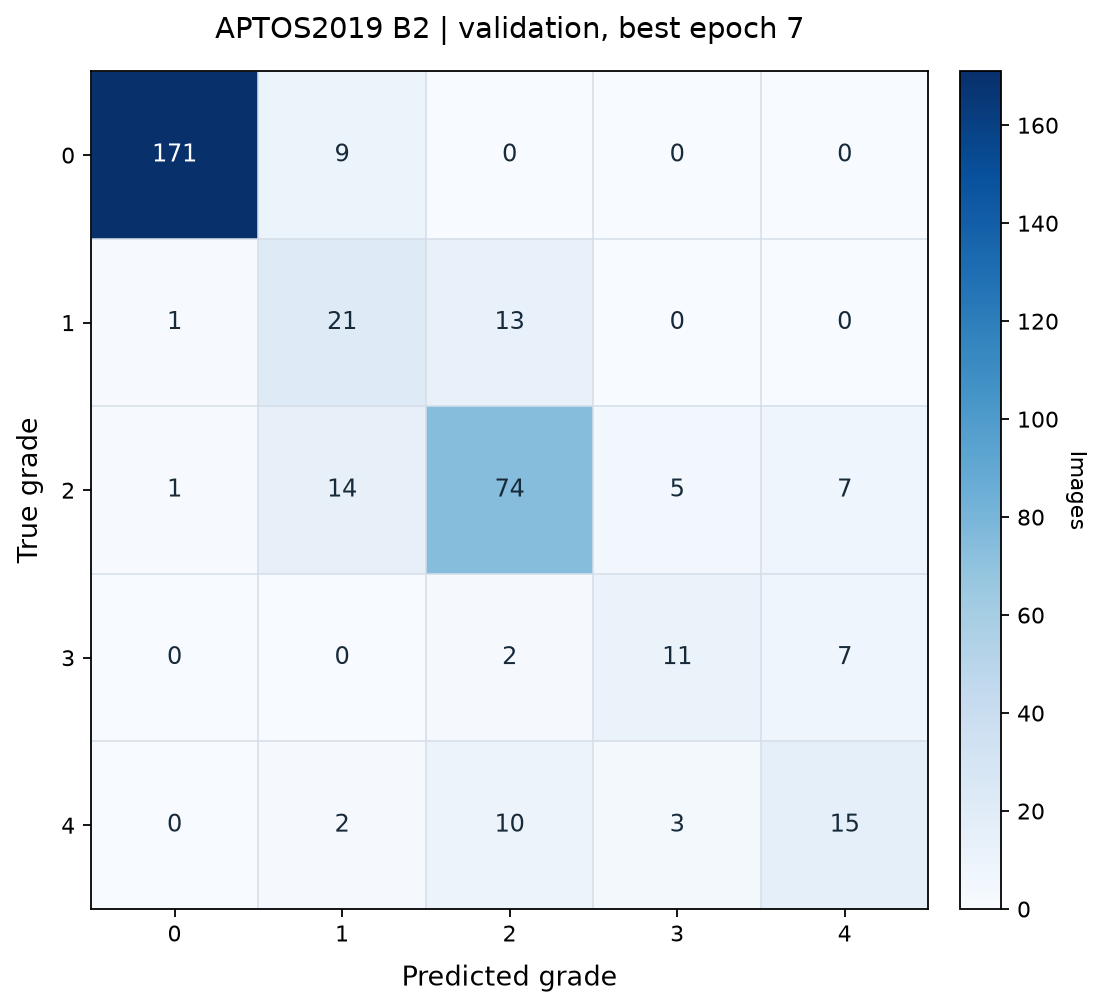

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B2_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

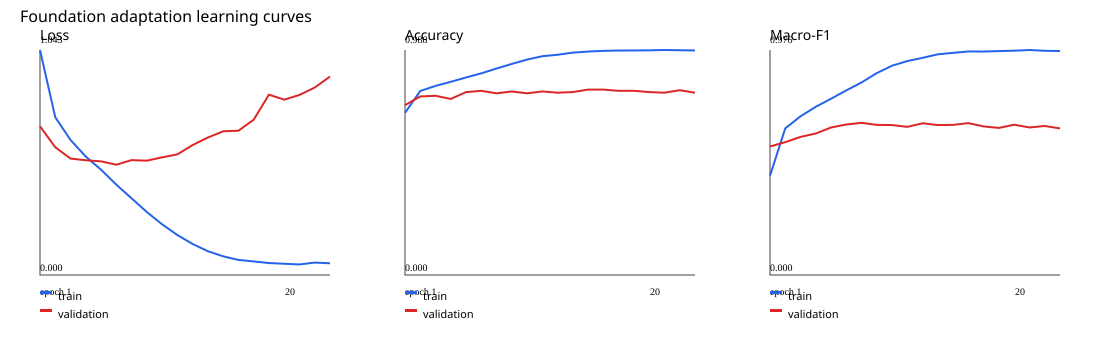

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B2_learning_curves.svg')))

## Interpretation and limits

Compared with B0 on this validation split, macro-F1 changed by -0.013700, grade 1 recall by -0.0571, and grade 3 recall by +0.0500.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})